#User-based Collaborative Filter (User-Item CF)

In [ ]:
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.feature_extraction.text import TfidfVectorizer
import numpy as np

In [ ]:
# Load the datasets
book_data = pd.read_csv('book_data_sample_ed.csv')
ratings_data = pd.read_csv('ratings_data_sample_ed.csv')
user_data = pd.read_csv('users_data_sample_ed.csv')

In [ ]:
# Step 1: Merge user_data with ratings_data to include age with each rating
merged_data = pd.merge(ratings_data, user_data[['User-ID', 'Age']], on='User-ID')

# Pivot to create user-item matrix, filling missing ratings with 0
user_item_matrix = merged_data.pivot_table(index='User-ID', columns='ISBN', values='Book-Rating', fill_value=0)

# Normalize the age feature and append it to the user-item matrix
# For simplicity in this example, we'll scale age to a 0-10 range to roughly match the book rating scale
# Preprocess the age data for clustering
user_data['Age'] = pd.to_numeric(user_data['Age'], errors='coerce').fillna(user_data['Age'].median())
scaler = StandardScaler()
age_scaled = scaler.fit_transform(user_data[['Age']])

# Convert 'Age' to numeric, handling errors by coercing them to NaN
user_data['Age'] = pd.to_numeric(user_data['Age'], errors='coerce')

# Fill NaN values with the median age
median_age = user_data['Age'].median()
user_data['Age'] = user_data['Age'].fillna(median_age)

# To extract the 'Age' column as a DataFrame instead of a Series
user_ages_df = user_data[['Age']]  # Note the double brackets to ensure it's a DataFrame

# If you want to set 'User-ID' as the index of this new DataFrame
user_ages_df = user_data.set_index('User-ID')[['Age']]

# If we need to scale ages, a couple of options:
# min-max scaling
#scaled_ages = (user_ages - user_ages.min()) / (user_ages.max() - user_ages.min()) * 10

# Using Z score normalization
scaler = StandardScaler()
#age_scaled = scaler.fit_transform(user_ages_df)

user_item_matrix['Age'] = user_ages_df

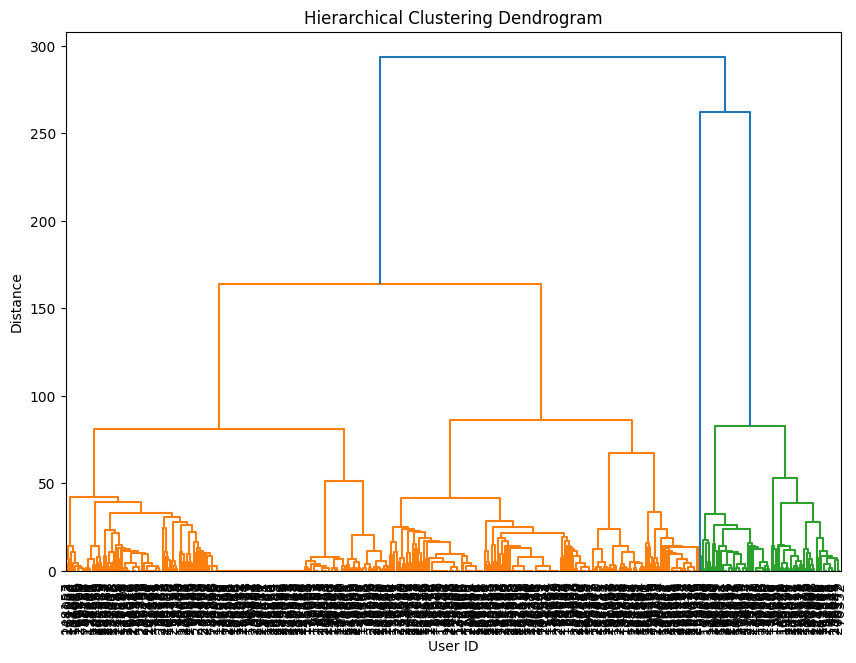

In [ ]:
# Hierarchical Clustering
# Inspect the hierarchical clustering dendrogram for a sample of the user-item matrix to determine k (number of clusters)

from scipy.cluster.hierarchy import dendrogram, linkage
import matplotlib.pyplot as plt

# Let's take a sample of the user-item matrix to reduce the computational load
user_item_sample = user_item_matrix.sample(n=500, random_state=42)  # Taking a small sample for visualization

# Perform hierarchical clustering on the sample
Z = linkage(user_item_sample, method='ward')

# Visualize the dendrogram
plt.figure(figsize=(10, 7))
dendrogram(Z, labels=user_item_sample.index.astype(str), leaf_rotation=90, leaf_font_size=10)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('User ID')
plt.ylabel('Distance')
plt.show()

In [ ]:
from scipy.sparse import csr_matrix
# Convert to CSR matrix to handle sparse data efficiently
user_item_matrix_csr = csr_matrix(user_item_matrix.fillna(0))

In [ ]:
# Perform KMeans clustering based on age
kmeans = KMeans(n_clusters=3, random_state=42)

# Add the cluster labels to the user_data DataFrame
user_data['Cluster'] = kmeans.fit_predict(user_item_matrix_csr)

# Display the distribution of users across clusters
user_data['Cluster'].value_counts()

/usr/local/lib/python3.10/dist-packages/sklearn/cluster/_kmeans.py:870: FutureWarning: The default value of `n_init` will change from 10 to 'auto' in 1.4. Set the value of `n_init` explicitly to suppress the warning
  warnings.warn(


1    758
0    293
2      1
Name: Cluster, dtype: int64

In [ ]:
user_data

,User-ID,Location,Age,Cluster
0,99,"franktown, colorado, usa",42.0,0
1,507,"dumas, arkansas, usa",34.0,1
2,1424,"north avoca, new south wales, australia",34.0,1
3,1848,"bellingham, washington, usa",22.0,1
4,2110,"charlotte, north carolina, usa",34.0,1
...,...,...,...,...
1047,275922,"groves, texas, usa",47.0,0
1048,275970,"pittsburgh, pennsylvania, usa",46.0,0
1049,277478,"schiedam, zuid-holland, netherlands",31.0,1
1050,278418,"omaha, nebraska, usa",34.0,1


In [ ]:
# Function to find the cluster a given age belongs to
# Note: we may not have user-item interaction data for the target user (cold start problem)
# Let's assume we only have the user's age; we will fill the unknown columns of the user-item matrix with 0
def find_cluster(target_age, kmeans_model, scaler, n_items):
    # Create a simulated feature vector with all item ratings set to 0 and age at the target value
    # Note: 'n_items' should be the number of items (books) in the user-item matrix, excluding the age column
    simulated_features = np.zeros(n_items + 1)  # +1 for the age feature

    # Normalize the target age using the same scaling applied to the age during clustering
    #simulated_features[-1] = (target_age - scaler.mean_[-1]) / scaler.scale_[-1]  # Assuming age is the last feature

    # If not normalizing age, use
    simulated_features[-1] = target_age  # Assuming age is the last feature

    # Predict the cluster for the simulated feature vector
    cluster_label = kmeans_model.predict([simulated_features])
    return cluster_label[0]

In [ ]:
# Define the target age for demonstration
target_age = 30  # Example age

# Since the age has been appended as the last column in the user-item matrix, we can use its shape to determine 'n_items'
n_items = user_item_matrix.shape[1] - 1  # Excluding the age column

target_cluster = find_cluster(target_age, kmeans, scaler, n_items)

# Identify users in the same cluster
users_in_target_cluster = user_data[user_data['Cluster'] == target_cluster]

In [ ]:
users_in_target_cluster

,User-ID,Location,Age,Cluster
1,507,"dumas, arkansas, usa",34.0,1
2,1424,"north avoca, new south wales, australia",34.0,1
3,1848,"bellingham, washington, usa",22.0,1
4,2110,"charlotte, north carolina, usa",34.0,1
5,2982,"montreal, quebec, canada",34.0,1
...,...,...,...,...
1044,275240,"bronxville, new york, usa",16.0,1
1045,275306,"tyler, texas, usa",24.0,1
1049,277478,"schiedam, zuid-holland, netherlands",31.0,1
1050,278418,"omaha, nebraska, usa",34.0,1


In [ ]:
# Find the top 25 books based on average ratings from these users
top_books = ratings_data[ratings_data['User-ID'].isin(users_in_target_cluster['User-ID'])]

top_books

,User-ID,ISBN,Book-Rating
0,277478,0786868716,0
1,278418,0140361219,0
2,278418,0394800168,10
3,278422,0060935464,9
5,507,0064400026,0
...,...,...,...
1207,273979,0439420105,0
1208,273979,0786868716,0
1209,274282,8423328651,10
1213,275240,0743477103,10


In [ ]:
top_books_avg_ratings = top_books.groupby('ISBN').agg({'Book-Rating': 'mean', 'User-ID': 'count'}).reset_index()
top_books_avg_ratings.rename(columns={'User-ID': 'Rating-Count'}, inplace=True)

top_books_avg_ratings

,ISBN,Book-Rating,Rating-Count
0,0001047973,9.000000,2
1,0030514924,0.000000,1
2,0060001941,3.250000,8
3,0060254920,4.363636,11
4,0060256656,5.888889,27
...,...,...,...
84,345316413X,0.000000,1
85,8423328651,10.000000,2
86,8440619537,0.000000,1
87,8478884599,6.000000,1


In [ ]:
top_25_books = top_books_avg_ratings.sort_values(by=['Book-Rating', 'Rating-Count'], ascending=False).head(25)

top_25_books

,ISBN,Book-Rating,Rating-Count
85,8423328651,10.000000,2
32,043955490X,10.000000,1
45,0613496744,10.000000,1
51,0679905278,10.000000,1
67,0881030392,10.000000,1
80,1854597892,10.000000,1
69,1551430096,9.333333,3
0,0001047973,9.000000,2
35,0451528905,9.000000,1
38,0500237549,9.000000,1


In [ ]:
# Merge with book data to get the details
top_25_books_details = top_25_books.merge(book_data, how = 'left',left_on='ISBN', right_on= 'ISBN')

top_25_books_details

,ISBN,Book-Rating,Rating-Count,book_name,title,description,genres,av_rating,num_rating,Year-Of-Publication,Book-Author,Publisher,Image-URL-S,_merge
0,8423328651,10.000000,2,book_7,1984,The new novel by George Orwell is the major wo...,"['Classics', 'Fiction', 'Science Fiction', 'Dy...",4.19,4201429,1998.0,George Orwell,La Marca Editora,http://images.amazon.com/images/P/8423328651.0...,both
1,043955490X,10.000000,1,book_37,harry potter and the goblet of fire (harry pot...,"It is the middle of the summer, but there is a...","['Fantasy', 'Young Adult', 'Fiction', 'Magic',...",4.58,3048651,2003.0,J. K. Rowling,Arthur A. Levine Books,http://images.amazon.com/images/P/043955490X.0...,both
2,0613496744,10.000000,1,book_34,harry potter and the goblet of fire,It is the summer holidays and soon Harry Potte...,"['Fantasy', 'Young Adult', 'Fiction', 'Magic',...",4.56,3397378,2002.0,J. K. Rowling,Sagebrush Bound,http://images.amazon.com/images/P/0613496744.0...,both
3,0679905278,10.000000,1,book_68,"oh, the places you'll go!","For out-starting upstarts of all ages, here is...","['Childrens', 'Picture Books', 'Fiction', 'Cla...",4.36,387581,1990.0,Seuss,Random House Books for Young Readers,http://images.amazon.com/images/P/0679905278.0...,both
4,0881030392,10.000000,1,book_51,the outsiders,The Outsiders is about two weeks in the life o...,"['Classics', 'Young Adult', 'Fiction', 'School...",4.12,1220608,1999.0,S. E. Hinton,Sagebrush Bound,http://images.amazon.com/images/P/0881030392.0...,both
5,1854597892,10.000000,1,book_5,animal farm,Librarian's note: There is an Alternate Cover ...,"['Classics', 'Fiction', 'Dystopia', 'Fantasy',...",3.98,3575172,2004.0,George Orwell,Nick Hern Books,http://images.amazon.com/images/P/1854597892.0...,both
6,1551430096,9.333333,3,book_94,"cold night, brittle light",As Chrissy's family waits for her father to co...,"['Fiction', 'Childrens']",4.38,65695,1994.0,Richard Thompson,Orca Book Publishers,http://images.amazon.com/images/P/1551430096.0...,both
7,0001047973,9.000000,2,book_42,brave new world,"The astonishing novel Brave New World, origina...","['Classics', 'Fiction', 'Science Fiction', 'Dy...",4.16,159408,1999.0,Aldous Huxley,Trafalgar Square Publishing,http://images.amazon.com/images/P/0001047973.0...,both
8,0451528905,9.000000,1,book_92,don quixote,Don Quixote has become so entranced by reading...,"['Classics', 'Fiction', 'Literature', 'Spanish...",3.89,254292,2003.0,Miguel De Cervantes Saavedra,Signet Classics,http://images.amazon.com/images/P/0451528905.0...,both
9,0500237549,9.000000,1,book_78,gifts of the nile: ancient egyptian faience,One of the ancient world's most beautiful form...,"['Fantasy', 'Young Adult', 'Romance', 'Fiction...",3.64,6158643,1998.0,Florence Dunn Friedman,Thames &amp; Hudson,http://images.amazon.com/images/P/0500237549.0...,both


# If required, we can now refine this candidate list using a content-based approach